<a href="https://colab.research.google.com/github/DrDourado/ME_640_Optimum_Design_Fall_2026/blob/main/ME_640_07_Robust_Design_Mean_Variance_Pareto_Lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ME 640 — Design Under Uncertainty and Robust Optimization
## Mean–Variance Methods, Compromise Solutions, and Pareto Efficiency

**Central question:** *If operating conditions fluctuate, should we choose the design with the best nominal performance or one that performs consistently?*

### Learning outcomes
1. Distinguish sensitivity analysis, uncertainty quantification (UQ), robust design, and reliability-based design.
2. Propagate an uncertain operating condition through a data-informed engineering model.
3. Estimate response **mean**, **variance**, and **standard deviation**.
4. Formulate and interpret mean–variance robust objectives.
5. Generate and interpret the Pareto-efficient set and choose compromise designs.
6. Recognize the assumptions and limitations of dataset-driven robust optimization.

**Dataset:** UCI *Yacht Hydrodynamics* (308 resistance observations, six input variables). Its original measurements come from yacht-hull experiments; this lecture uses a trained empirical model to illustrate design decisions, **not** a validated naval-architecture optimization tool.

## 1. Four questions that should not be confused

| Topic | Central question | Typical mathematical quantity | What it does **not** directly answer |
|---|---|---|---|
| **Sensitivity analysis** | Which inputs influence the output, and how strongly? | $\partial f/\partial x_i$ or variance-based sensitivity indices | How uncertain is the output? |
| **Uncertainty quantification (UQ)** | What distribution of responses results from uncertain inputs? | $p_Y(y)$, $\mathbb{E}[Y]$, $\mathrm{Var}(Y)$ | Which design should be selected? |
| **Robust design** | Which design performs well *and consistently* across uncertain conditions? | $\min_d\;\mu_Y(d)+\lambda\sigma_Y(d)$ | Whether a strict failure-probability target is met |
| **Reliability-based design (RBDO)** | Does the design satisfy a probabilistic limit state? | $P[g(d,\xi)\leq 0]\leq\alpha$ | Whether it has the lowest response variability |

Let $d$ be a **controllable design**, $\xi$ an **uncertain operating variable**, and $Y=f(d,\xi)$ the performance response. The key distinction is between choosing $d$ and observing $\xi$.

**Example:** The hull geometry is selected before deployment; vessel speed fluctuates around its target due to operating conditions. We seek low and stable resistance.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import norm
from scipy.spatial.distance import cdist
SEED=640
rng=np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize':(8,4.8),'axes.grid':True,'grid.alpha':0.22})

### Visual intuition: sensitivity, UQ, robustness, reliability

The following **illustrative functions are not yacht data**. They isolate the four concepts before the case study.

- **Sensitivity:** the local slope of performance with respect to an uncertain input.
- **UQ:** uncertainty in the input induces a distribution of possible outputs.
- **Robustness:** two designs may have similar nominal output but different output spread.
- **Reliability:** probability of crossing a defined unacceptable-performance threshold.

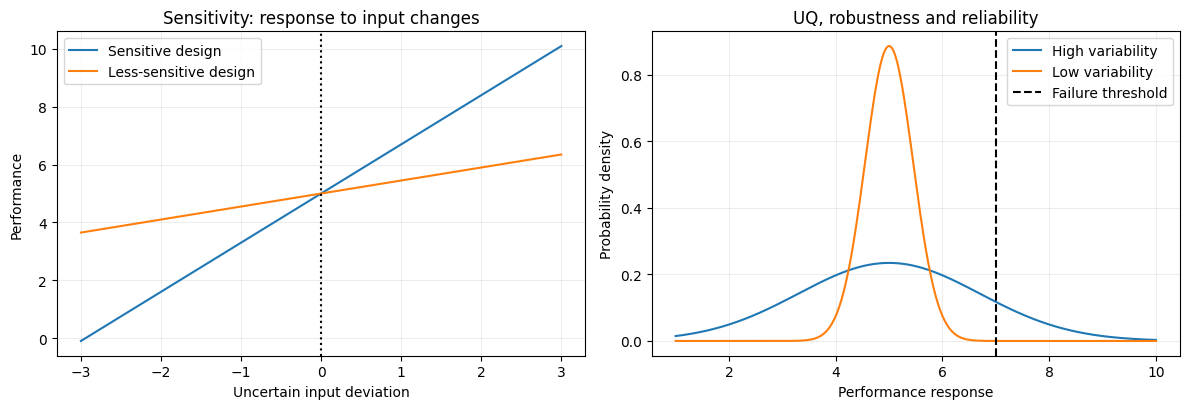

In [ ]:
z=np.linspace(-3,3,250)
fig,ax=plt.subplots(1,2,figsize=(12,4.2))
ax[0].plot(z,5+1.7*z,label='Sensitive design')
ax[0].plot(z,5+.45*z,label='Less-sensitive design')
ax[0].axvline(0,ls=':',color='k');ax[0].set(xlabel='Uncertain input deviation',ylabel='Performance',title='Sensitivity: response to input changes');ax[0].legend()
x=np.linspace(1,10,400)
for mu,sig,label in [(5,1.7,'High variability'),(5,.45,'Low variability')]:
 ax[1].plot(x,norm.pdf(x,mu,sig),label=label)
ax[1].axvline(7,color='k',ls='--',label='Failure threshold')
ax[1].set(xlabel='Performance response',ylabel='Probability density',title='UQ, robustness and reliability');ax[1].legend()
plt.tight_layout();plt.show()

## 2. Deterministic versus uncertain performance

A deterministic design selects the geometry with the smallest response at one assumed operating condition:

$$d^*_{\mathrm{nom}}=\arg\min_{d\in\mathcal D}f(d,\xi_0).$$

Under uncertain operating conditions $\xi\sim p(\xi)$, the response is itself a random variable:

$$Y(d)=f(d,\xi),\qquad \mu(d)=\mathbb E_{\xi}[Y(d)],\qquad
\sigma^2(d)=\mathbb E_{\xi}[(Y(d)-\mu(d))^2].$$

A nominal optimum can be fragile: its performance may deteriorate rapidly when $\xi$ deviates from $\xi_0$. A robust optimum deliberately accounts for this variability.

**Interpretation:** Mean is expected performance; variance is squared spread; standard deviation has the same units as the response. A lower variance does not automatically mean a lower mean.

## 3. Engineering dataset: yacht hydrodynamic resistance

The public UCI dataset ([original](https://archive.ics.uci.edu/dataset/243/yacht+hydrodynamics) and [Kaggle](https://www.kaggle.com/datasets/heitornunes/yacht-hydrodynamics-data-set/data)) records six input variables and a nondimensional resistance response:

1. Longitudinal position of the center of buoyancy
2. Prismatic coefficient
3. Length–displacement ratio
4. Beam–draught ratio
5. Length–beam ratio
6. Froude number (speed-related operating variable)

**Response:** Residuary resistance per unit displacement weight (nondimensional).

We treat the first five variables as **candidate hull descriptors** and the Froude number as an **uncertain operating variable**. We compare hull configurations observed in the dataset, avoiding arbitrary synthetic combinations of geometry.

> The notebook tries the UCI download first. For offline instruction, place `yacht_hydrodynamics.data` in the notebook directory. A transparent synthetic *demonstration-only* fallback is included if neither is available; it is **not** the UCI dataset.

In [ ]:
COLS=['LCB','Prismatic','LengthDisp','BeamDraught','LengthBeam','Froude','Resistance']
URL='https://archive.ics.uci.edu/ml/machine-learning-databases/00243/yacht_hydrodynamics.data'
source='UCI Yacht Hydrodynamics'
try:
    df=pd.read_csv(URL,sep=r'\s+',header=None,names=COLS,engine='python')
    if df.shape[1]!=7 or len(df)<250: raise ValueError('Unexpected dataset format')
except Exception:
    local=Path('yacht_hydrodynamics.data')
    if local.exists():
        df=pd.read_csv(local,sep=r'\s+',header=None,names=COLS,engine='python')
        source='local UCI dataset file'
    else:
        source='SYNTHETIC DEMONSTRATION ONLY — not the UCI dataset'
        rr=np.random.default_rng(SEED)
        hull=np.column_stack([rr.uniform(-4,0,22),rr.uniform(.52,.60,22),rr.uniform(4.3,5.2,22),rr.uniform(2.5,3.7,22),rr.uniform(2.7,3.3,22)])
        rows=[]
        for h in hull:
            for f in np.linspace(.125,.45,14):
                # Constructed response: different hulls have different speed sensitivity.
                a=1.0+2*(h[1]-.52)+.10*(h[2]-4.3)
                y=1.2+4*(f/.45)**2*a+16*(f/.45)**4*(.9+.25*(h[3]-2.5)) + .3*(h[0]+2)**2
                rows.append([*h,f,y])
        df=pd.DataFrame(rows,columns=COLS)
print('DATA SOURCE:',source,'| Rows:',len(df))
display(df.head())

DATA SOURCE: UCI Yacht Hydrodynamics | Rows: 308


,LCB,Prismatic,LengthDisp,BeamDraught,LengthBeam,Froude,Resistance
0,-2.3,0.568,4.78,3.99,3.17,0.125,0.11
1,-2.3,0.568,4.78,3.99,3.17,0.150,0.27
2,-2.3,0.568,4.78,3.99,3.17,0.175,0.47
3,-2.3,0.568,4.78,3.99,3.17,0.200,0.78
4,-2.3,0.568,4.78,3.99,3.17,0.225,1.18


In [ ]:
# --- Statistical Summary ---
df.describe().T.style.background_gradient(cmap='Blues')

,count,mean,std,min,25%,50%,75%,max
LCB,308.000000,-2.381818,1.513219,-5.000000,-2.400000,-2.300000,-2.300000,0.000000
Prismatic,308.000000,0.564136,0.023290,0.530000,0.546000,0.565000,0.574000,0.600000
LengthDisp,308.000000,4.788636,0.253057,4.340000,4.770000,4.780000,5.100000,5.140000
BeamDraught,308.000000,3.936818,0.548193,2.810000,3.750000,3.955000,4.170000,5.350000
LengthBeam,308.000000,3.206818,0.247998,2.730000,3.150000,3.150000,3.510000,3.640000
Froude,308.000000,0.287500,0.100942,0.125000,0.200000,0.287500,0.375000,0.450000
Resistance,308.000000,10.495357,15.160490,0.010000,0.777500,3.065000,12.815000,62.420000


In [ ]:
# --- Correlation Analysis ---
corr = df.corr()
print('\n Correlation with Target:')
print(corr['Resistance'].sort_values(ascending=False).to_string())


 Correlation with Target:
Resistance     1.000000
Froude         0.810092
LCB            0.019306
LengthBeam    -0.001025
LengthDisp    -0.002967
BeamDraught   -0.012421
Prismatic     -0.028569


### What the dataset can and cannot establish

The observed experiments support learning a relationship between the recorded hull variables, Froude number, and resistance. **They do not provide a probability distribution for real operating speeds** or guarantee predictions at untested geometries/speeds. Our speed-uncertainty distribution below is a stated **teaching assumption**. The model's prediction error is distinct from operating-condition uncertainty.

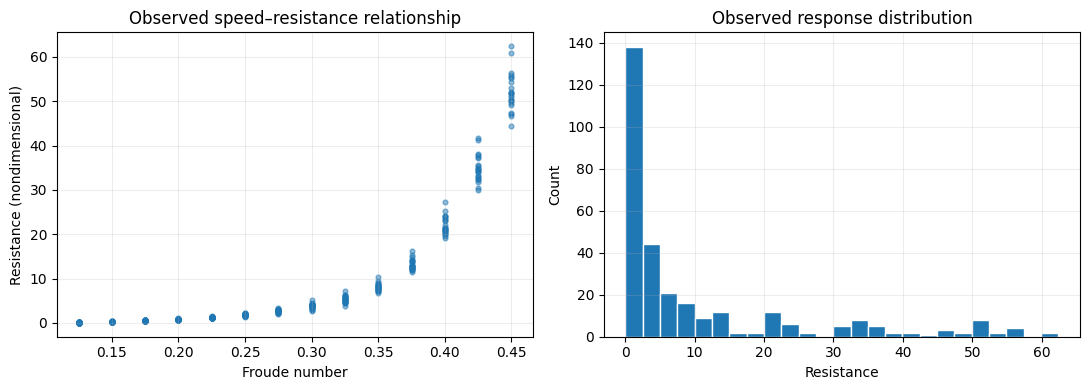

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(df.Froude,df.Resistance,s=12,alpha=.5)
ax[0].set(xlabel='Froude number',ylabel='Resistance (nondimensional)',title='Observed speed–resistance relationship')
ax[1].hist(df.Resistance,bins=25,edgecolor='white')
ax[1].set(xlabel='Resistance',ylabel='Count',title='Observed response distribution')
plt.tight_layout();plt.show()

## 4. Fit a predictive model as an engineering response evaluator

We fit a Random Forest regressor to the public observations, reserving a holdout set to assess prediction quality. The fitted model is an **empirical response surrogate**, not an exact physical law.

$$\hat R(d,F)=\frac{1}{B}\sum_{b=1}^{B}T_b(d,F).$$

Here, we evaluate a set of observed hull geometries at multiple possible Froude numbers. Restricting comparisons to observed geometries reduces,but does not eliminate,extrapolation risk.

Holdout MAE: 0.706; R²: 0.992


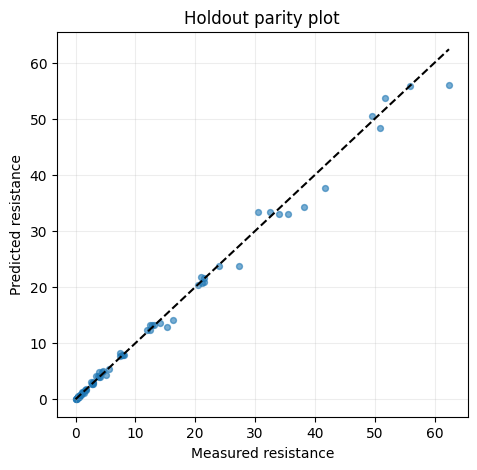

In [ ]:
features=COLS[:-1]
X_train,X_test,y_train,y_test=train_test_split(df[features],df.Resistance,test_size=.22,random_state=SEED)
model=RandomForestRegressor(n_estimators=250,min_samples_leaf=2,random_state=SEED,n_jobs=-1)
model.fit(X_train,y_train)
pred=model.predict(X_test)
print(f'Holdout MAE: {mean_absolute_error(y_test,pred):.3f}; R²: {r2_score(y_test,pred):.3f}')
fig,ax=plt.subplots(figsize=(5.3,5))
ax.scatter(y_test,pred,s=18,alpha=.6)
lim=[min(y_test.min(),pred.min()),max(y_test.max(),pred.max())]
ax.plot(lim,lim,'k--');ax.set(xlabel='Measured resistance',ylabel='Predicted resistance',title='Holdout parity plot')
plt.show()

## 5. Sensitivity and uncertainty propagation

**Sensitivity** studies the change in output when an input changes. A finite-difference estimate at nominal Froude number $F_0$ is

$$S_F(d;F_0)\approx\frac{\hat R(d,F_0+h)-\hat R(d,F_0-h)}{2h}.$$

**UQ** instead asks how a distribution of Froude numbers produces a distribution of resistance. We assume

$$F\sim\mathcal N(F_0,\sigma_F^2)\quad\text{truncated to a feasible operating interval}.$$

For each design $d$, Monte Carlo propagation approximates

$$\hat\mu_R(d)=\frac1N\sum_{k=1}^N\hat R(d,F_k),\qquad
\hat\sigma_R^2(d)=\frac1{N-1}\sum_{k=1}^N[\hat R(d,F_k)-\hat\mu_R(d)]^2.$$

**Common random numbers:** use the same sampled $F_k$ for every candidate design to make comparisons less noisy.

In [ ]:
df['Froude'].mean(),df['Froude'].std(),df['Froude'].min(),df['Froude'].max()

(np.float64(0.28750000000000003), 0.10094222232325288, 0.125, 0.45)

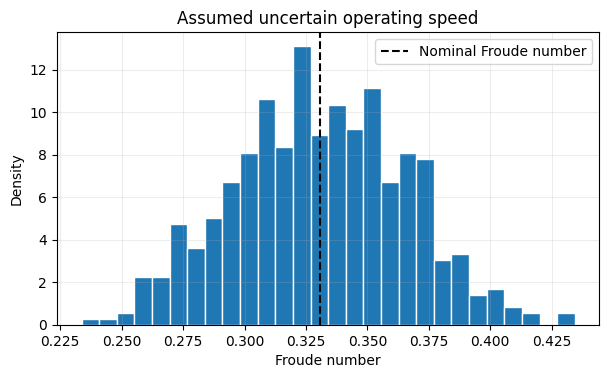

In [ ]:
F0=df['Froude'].mean()*1.15; SIGMA_F=df['Froude'].std()/3; F_MIN=df['Froude'].min(); F_MAX=df['Froude'].max()
N_MC=500
from scipy.stats import truncnorm
lo=(F_MIN-F0)/SIGMA_F;hi=(F_MAX-F0)/SIGMA_F
F_samples=truncnorm.rvs(lo,hi,loc=F0,scale=SIGMA_F,size=N_MC,random_state=SEED)
fig,ax=plt.subplots(figsize=(7,3.8))
ax.hist(F_samples,bins=28,edgecolor='white',density=True)
ax.axvline(F0,color='k',ls='--',label='Nominal Froude number')
ax.set(xlabel='Froude number',ylabel='Density',title='Assumed uncertain operating speed');ax.legend();plt.show()

### Propagation: compare two candidate hulls

We begin with two observed hull geometries. Their resistance distributions can have different means and spreads even under the **same speed uncertainty**.

Unique observed hull geometries: 22


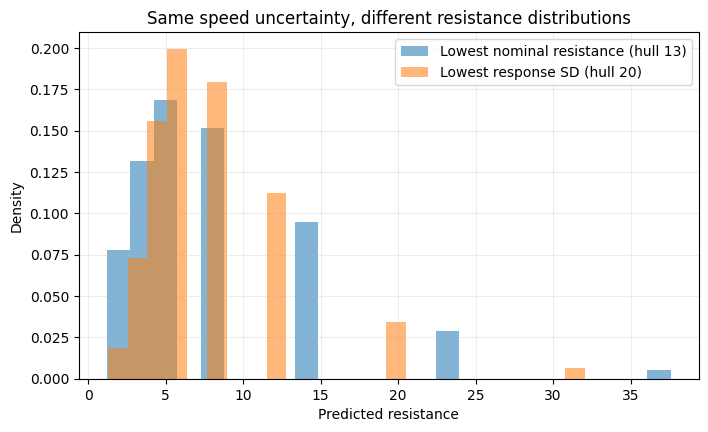

Nominal-best hull: 13 mean: 7.186 SD: 5.717
Minimum-SD hull: 20 mean: 7.614 SD: 4.529


In [ ]:
hull_cols=features[:-1]
hulls=df[hull_cols].drop_duplicates().reset_index(drop=True)
print('Unique observed hull geometries:',len(hulls))
def evaluate_hulls(hulls,F_values):
    h=hulls.to_numpy(dtype=float)
    nH,nF=len(h),len(F_values)
    X=np.repeat(h,nF,axis=0)
    X=np.column_stack([X,np.tile(F_values,nH)])
    Y=model.predict(pd.DataFrame(X,columns=features)).reshape(nH,nF)
    return Y
Y=evaluate_hulls(hulls,F_samples)
mu=Y.mean(axis=1);sd=Y.std(axis=1,ddof=1)
nom=evaluate_hulls(hulls,np.array([F0])).ravel()
# Select two demonstrative hulls: minimum nominal resistance and minimum response variability.
i_nom=int(np.argmin(nom));i_stable=int(np.argmin(sd))
fig,ax=plt.subplots(figsize=(8,4.5))
for i,label in [(i_nom,'Lowest nominal resistance'),(i_stable,'Lowest response SD')]:
    ax.hist(Y[i],bins=24,alpha=.55,density=True,label=f'{label} (hull {i})')
ax.set(xlabel='Predicted resistance',ylabel='Density',title='Same speed uncertainty, different resistance distributions')
ax.legend();plt.show()
print('Nominal-best hull:',i_nom,'mean:',round(mu[i_nom],3),'SD:',round(sd[i_nom],3))
print('Minimum-SD hull:',i_stable,'mean:',round(mu[i_stable],3),'SD:',round(sd[i_stable],3))

## 6. Variance-based robust optimization

A robust design seeks **low expected resistance** and **low variability** in resistance:

$$\boxed{\min_{d\in\mathcal D}\;\big[\mu_R(d),\;\sigma_R(d)\big].}$$

This is a two-objective problem. A common scalar alternative is the mean–standard-deviation formulation

$$\boxed{d^*(\lambda)=\arg\min_{d\in\mathcal D}\;\mu_R(d)+\lambda\sigma_R(d),\qquad\lambda\ge0.}$$

Here $\lambda$ controls the preference for consistency relative to average performance. **Both terms have the same units**, so $\lambda$ is dimensionless. If variance is used instead,

$$\min_d\;\mu_R(d)+\gamma\sigma_R^2(d),$$

then $\gamma$ must have reciprocal-response units; its numerical value is not interchangeable with $\lambda$.

**Why not simply minimize variance?** A design could be consistently poor. Robust design needs an explicit performance/variability compromise.

,lambda,Hull index,Mean resistance,Resistance SD,Nominal resistance
0,0.0,1,6.7850,5.0142,4.8847
1,0.5,1,6.7850,5.0142,4.8847
2,1.0,1,6.7850,5.0142,4.8847
3,2.0,7,7.2932,4.6347,5.5758
4,4.0,20,7.6139,4.5289,6.1621


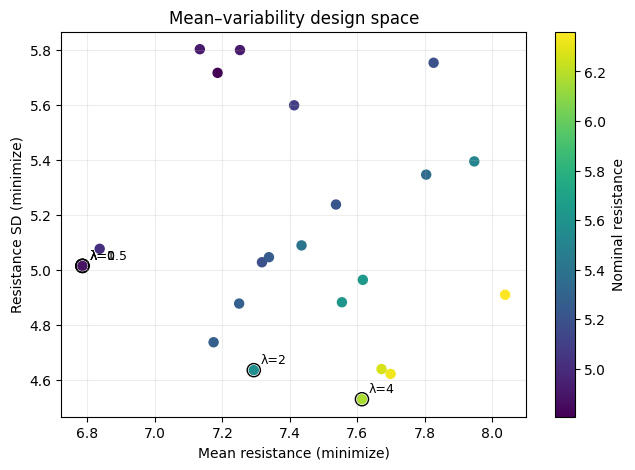

In [ ]:
lam_values=[0,.5,1,2,4]
chosen=[]
for lam in lam_values:
    j=int(np.argmin(mu+lam*sd))
    chosen.append([lam,j,mu[j],sd[j],nom[j]])
display(pd.DataFrame(chosen,columns=['lambda','Hull index','Mean resistance','Resistance SD','Nominal resistance']).round(4))
fig,ax=plt.subplots(figsize=(7.5,5))
sc=ax.scatter(mu,sd,c=nom,cmap='viridis',s=42)
for lam,j,_,_,_ in chosen:
 ax.scatter(mu[j],sd[j],s=90,edgecolor='k',facecolor='none')
 ax.annotate(f'λ={lam}',(mu[j],sd[j]),xytext=(5,5),textcoords='offset points',fontsize=9)
ax.set(xlabel='Mean resistance (minimize)',ylabel='Resistance SD (minimize)',title='Mean–variability design space')
plt.colorbar(sc,ax=ax,label='Nominal resistance');plt.show()

## 7. Pareto efficiency: which compromises are defensible?

Design $a$ **dominates** design $b$ if

$$\mu_a\le\mu_b,\qquad\sigma_a\le\sigma_b,$$

with at least one strict inequality. A design is **Pareto-efficient** if no other candidate dominates it.

- Points **on** the Pareto front represent meaningful tradeoffs.
- Points **above/right** of the front are dominated: another candidate is at least as good in both objectives.
- There is generally **no unique best design** without additional preferences.

The Pareto front shows the tradeoff; a decision-maker then selects a compromise.

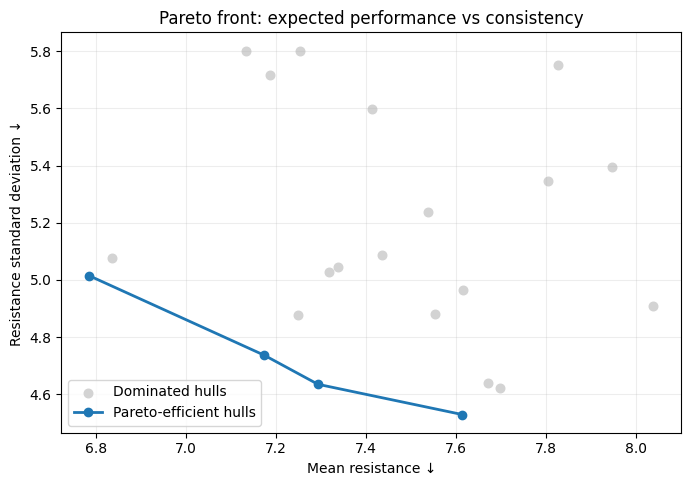

Pareto-efficient hulls: 4 of 22


In [ ]:
def pareto_mask_two_min(a,b):
    # Vectorized dominance for two objectives to minimize.
    A=np.column_stack([a,b]); mask=np.ones(len(A),dtype=bool)
    for i in range(len(A)):
        dominated=np.all(A<=A[i],axis=1)&np.any(A<A[i],axis=1)
        if dominated.any():mask[i]=False
    return mask
is_pareto=pareto_mask_two_min(mu,sd)
fig,ax=plt.subplots(figsize=(8,5.2))
ax.scatter(mu[~is_pareto],sd[~is_pareto],color='lightgray',s=38,label='Dominated hulls')
order=np.argsort(mu[is_pareto]);pm=mu[is_pareto][order];ps=sd[is_pareto][order]
ax.plot(pm,ps,'o-',color='tab:blue',lw=2,label='Pareto-efficient hulls')
ax.set(xlabel='Mean resistance ↓',ylabel='Resistance standard deviation ↓',title='Pareto front: expected performance vs consistency')
ax.legend();plt.show()
print('Pareto-efficient hulls:',is_pareto.sum(),'of',len(hulls))

## 8. Selecting a compromise solution

The Pareto set is a set of alternatives, not a final answer. Two common ways to select a compromise are:

### A. Weighted-sum compromise
$$d^*(\lambda)=\arg\min_d\mu(d)+\lambda\sigma(d).$$

**Interpretation:** increasing $\lambda$ assigns greater value to stable performance. However, weighted sums may fail to recover points on a nonconvex part of the Pareto front.

### B. Ideal-point (utopia-point) compromise

The ideal point combines the best separately achievable values:

$$z^{ideal}=\big(\min_d\mu(d),\;\min_d\sigma(d)\big).$$

Usually no single design achieves both. Normalize each objective by its observed range and minimize distance to the ideal:

$$d^*_{ideal}=\arg\min_d\sqrt{\left(\frac{\mu(d)-\mu_{min}}{\mu_{max}-\mu_{min}}\right)^2+\left(\frac{\sigma(d)-\sigma_{min}}{\sigma_{max}-\sigma_{min}}\right)^2}.$$

**Important:** the ideal-point choice depends on normalization and the chosen distance metric. It is one transparent preference rule, not an objective physical truth.

,Decision rule,Hull index,Mean resistance,Resistance SD
0,Minimum mean,1,6.7850,5.0142
1,Minimum variability,20,7.6139,4.5289
2,Ideal-point compromise,0,7.1740,4.7362


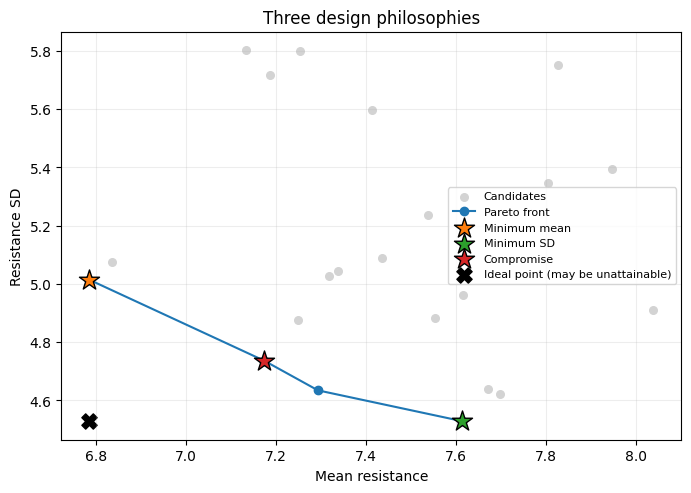

In [ ]:
mu_norm=(mu-mu.min())/(np.ptp(mu)+1e-12)
sd_norm=(sd-sd.min())/(np.ptp(sd)+1e-12)
distance=np.hypot(mu_norm,sd_norm)
i_ideal=int(np.argmin(distance))
i_mean=int(np.argmin(mu));i_sd=int(np.argmin(sd))
choices=pd.DataFrame([
    ['Minimum mean',i_mean,mu[i_mean],sd[i_mean]],
    ['Minimum variability',i_sd,mu[i_sd],sd[i_sd]],
    ['Ideal-point compromise',i_ideal,mu[i_ideal],sd[i_ideal]]
],columns=['Decision rule','Hull index','Mean resistance','Resistance SD'])
display(choices.round(4))
fig,ax=plt.subplots(figsize=(8,5.3))
ax.scatter(mu,sd,color='lightgray',s=30,label='Candidates')
ax.plot(pm,ps,'o-',color='tab:blue',label='Pareto front')
for name,j,col in [('Minimum mean',i_mean,'tab:orange'),('Minimum SD',i_sd,'tab:green'),('Compromise',i_ideal,'tab:red')]:
 ax.scatter(mu[j],sd[j],marker='*',s=230,color=col,edgecolor='k',label=name,zorder=5)
ax.scatter(mu.min(),sd.min(),marker='X',s=120,color='k',label='Ideal point (may be unattainable)')
ax.set(xlabel='Mean resistance',ylabel='Resistance SD',title='Three design philosophies')
ax.legend(loc='best',fontsize=8);plt.show()

### Visualize the engineering consequence of compromise

The following curves use the **same range of operating speeds** for the selected hulls. Compare both the resistance level and how rapidly it increases with speed.

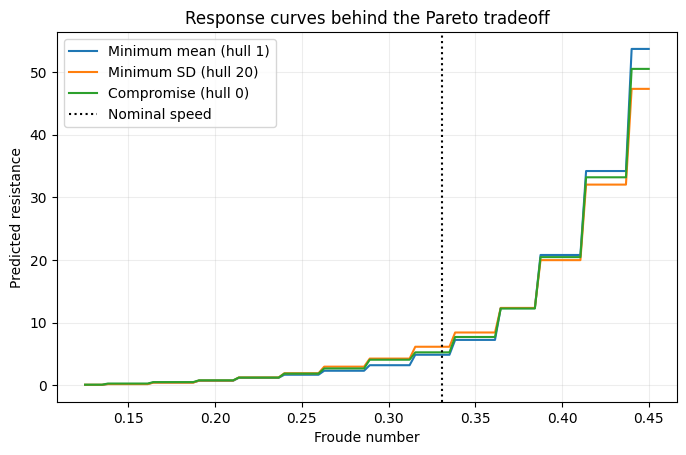

In [ ]:
F_grid=np.linspace(F_MIN,F_MAX,100)
fig,ax=plt.subplots(figsize=(8,4.8))
for name,j in [('Minimum mean',i_mean),('Minimum SD',i_sd),('Compromise',i_ideal)]:
 ycurve=evaluate_hulls(hulls.iloc[[j]],F_grid).ravel()
 ax.plot(F_grid,ycurve,label=f'{name} (hull {j})')
ax.axvline(F0,color='k',ls=':',label='Nominal speed')
ax.set(xlabel='Froude number',ylabel='Predicted resistance',title='Response curves behind the Pareto tradeoff')
ax.legend();plt.show()

## 9. What changes when uncertainty changes?

Robustness is **distribution-dependent**. A design selected for $F\sim p_1(F)$ may not remain optimal under a wider or shifted distribution $p_2(F)$.

Re-evaluate the candidate hulls for several standard deviations, keeping the nominal speed fixed. This is an uncertainty-assumption sensitivity study, **not** a Sobol analysis: Sobol indices partition response variance among multiple uncertain inputs, while this lecture focuses on how variance enters the **design objective**.

In [ ]:
results=[]
for sig in [.015,.035,.06]:
 rr=np.random.default_rng(640)
 F=truncnorm.rvs((F_MIN-F0)/sig,(F_MAX-F0)/sig,loc=F0,scale=sig,size=350,random_state=rr)
 YY=evaluate_hulls(hulls,F)
 mm=YY.mean(axis=1);ss=YY.std(axis=1,ddof=1)
 j=int(np.argmin(mm+1.0*ss))
 results.append([sig,j,mm[j],ss[j]])
display(pd.DataFrame(results,columns=['Assumed Froude SD','Selected hull (λ=1)','Mean resistance','Resistance SD']).round(4))

,Assumed Froude SD,Selected hull (λ=1),Mean resistance,Resistance SD
0,0.015,1,5.5314,1.5632
1,0.035,1,6.7138,5.4945
2,0.060,20,9.1710,8.9952


## 10. Practical cautions in data-informed robust design

1. **Uncertain inputs versus design variables:** do not optimize over a random variable as if it were fully controllable.
2. **Uncertainty assumptions:** state the distribution, parameters, bounds, and source; scenario results depend on them.
3. **Surrogate error:** $\hat R$ is not the true response. Operating variability and prediction error are different sources of uncertainty.
4. **Data coverage:** a model may behave poorly outside measured combinations; restrict or verify candidates.
5. **Correlation:** if several uncertain inputs are modeled, preserve physical correlations rather than independently sampling by default.
6. **Monte Carlo error:** means, SDs, and exceedance probabilities are estimates; use convergence checks or confidence intervals for consequential decisions.
7. **Objective scaling:** weighted sums and ideal-point distances are sensitive to scaling and preference assumptions.
8. **Engineering feasibility:** a Pareto-efficient candidate can still violate cost, geometry, safety, or manufacturing constraints.

**When are variance-based sensitivity methods appropriate?** First-order and total-effect Sobol indices can diagnose which uncertain inputs contribute most to output variance, but they are not themselves robust objective functions. They answer a different question from the mean–variance tradeoff studied here.

## 11. Lecture synthesis and discussion

**Four distinct questions**

- *Sensitivity:* Which uncertain input most changes resistance?
- *UQ:* What distribution of resistance results from uncertain speed?
- *Robustness:* Which hull has an attractive combination of low mean and low spread?
- *Reliability:* Which hull meets a specified failure-probability requirement?

**Core workflow**

$$\boxed{\text{Design candidates}\to\text{uncertainty model}\to\text{propagation}\to(\mu,\sigma)\to\text{Pareto front}\to\text{compromise}\to\text{verification}}$$

### In-class discussion
1. Why might the lowest nominal-resistance hull not be the most robust?
2. Can a dominated design ever be preferable if we later introduce new constraints or objectives?
3. What changes when the operator prioritizes average performance over consistency?
4. Is the ideal-point compromise guaranteed to be physically attainable?
5. Why does a small resistance SD not prove a low failure probability?
6. What additional information would be needed to recommend an actual yacht hull?

### Optional extension
Repeat the Pareto analysis for several speed-uncertainty levels and plot the movement of the compromise point. If time permits, compare mean–SD and mean–variance penalties, taking care to distinguish the units of their weights.

**Dataset reference:** Gerritsma, Onnink & Versluis, *Yacht Hydrodynamics*, UCI Machine Learning Repository, DOI: 10.24432/C5XG7R.